In [ ]:
import os
import urllib.request
import zipfile

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00240/UCI%20HAR%20Dataset.zip"
zip_path = "UCI_HAR_Dataset.zip"
extract_dir = "UCI HAR Dataset"

if not os.path.exists(extract_dir):
    urllib.request.urlretrieve(url, zip_path)
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(".")

print("Főkönyvtár:", os.listdir(extract_dir))
print("Nyers jelek:", os.listdir(os.path.join(extract_dir, "train", "Inertial Signals")))

Főkönyvtár: ['activity_labels.txt', 'test', '.DS_Store', 'README.txt', 'features.txt', 'features_info.txt', 'train']
Nyers jelek: ['body_acc_y_train.txt', 'body_gyro_y_train.txt', 'body_acc_x_train.txt', 'body_gyro_z_train.txt', 'total_acc_y_train.txt', 'body_acc_z_train.txt', 'total_acc_x_train.txt', 'total_acc_z_train.txt', 'body_gyro_x_train.txt']


/tmp/ipykernel_1073/2988905383.py:27: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  data = pd.read_csv(filename, delim_whitespace=True, header=None).values
/tmp/ipykernel_1073/2988905383.py:27: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  data = pd.read_csv(filename, delim_whitespace=True, header=None).values
/tmp/ipykernel_1073/2988905383.py:27: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  data = pd.read_csv(filename, delim_whitespace=True, header=None).values
/tmp/ipykernel_1073/2988905383.py:27: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  data = pd.read_csv(filename, delim_whitespace=True, head

Train alakja: (7352, 128, 9) | Test alakja: (2947, 128, 9)
Hiányzó értékek (Train / Test): 0 / 0
Végtelen értékek (Train / Test): 0 / 0
Train alanyok (21 fő): [ 1  3  5  6  7  8 11 14 15 16 17 19 21 22 23 25 26 27 28 29 30]
Test alanyok (9 fő): [ 2  4  9 10 12 13 18 20 24]
Átfedés az alanyok között: []

Csatornánkénti statisztika (Train):
   Csatorna   Átlag  Szórás     Min    Max
 body_acc_x -0.0006  0.1948 -1.2322 1.2999
 body_acc_y -0.0003  0.1224 -1.3453 0.9760
 body_acc_z -0.0003  0.1069 -1.3647 1.0669
body_gyro_x  0.0005  0.4068 -4.7337 4.1555
body_gyro_y -0.0008  0.3819 -5.9743 5.7461
body_gyro_z  0.0001  0.2557 -2.7630 2.3660
total_acc_x  0.8047  0.4141 -0.4666 2.1976
total_acc_y  0.0288  0.3910 -1.5821 1.2174
total_acc_z  0.0865  0.3578 -1.6396 1.2814

Osztályeloszlás:
                    Train db  Test db  Train %  Test %
LAYING                  1407      537    19.14   18.22
SITTING                 1286      491    17.49   16.66
STANDING                1374      532    18.69

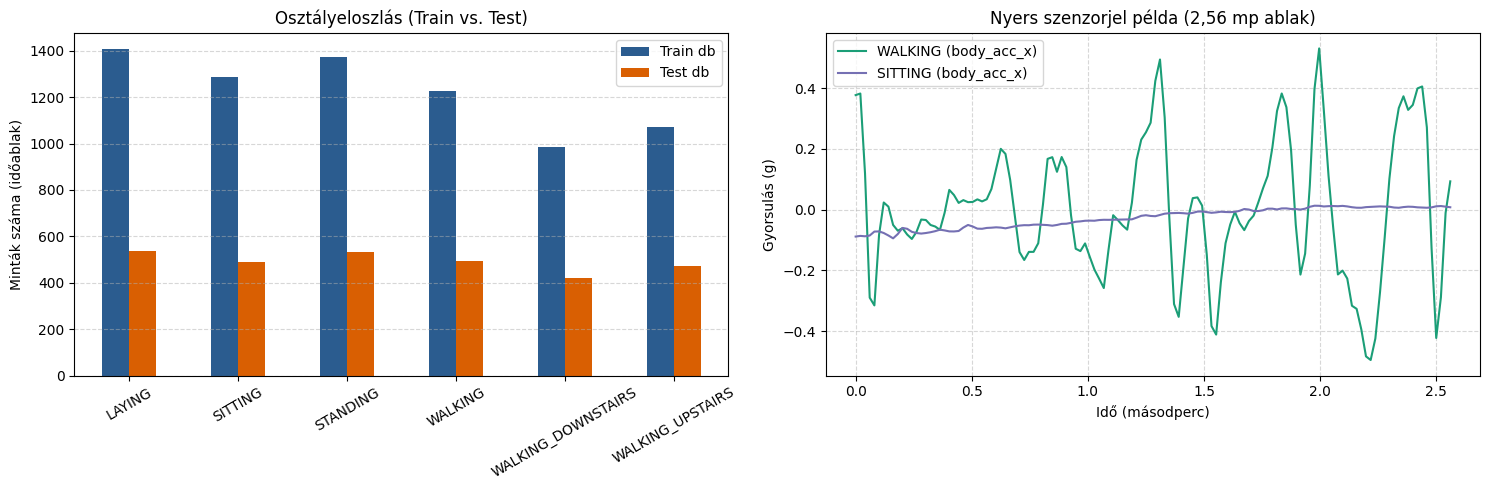

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATASET_PATH = "UCI HAR Dataset/"

SIGNALS = [
    "body_acc_x", "body_acc_y", "body_acc_z",
    "body_gyro_x", "body_gyro_y", "body_gyro_z",
    "total_acc_x", "total_acc_y", "total_acc_z"
]

ACTIVITY_LABELS = {
    1: "WALKING",
    2: "WALKING_UPSTAIRS",
    3: "WALKING_DOWNSTAIRS",
    4: "SITTING",
    5: "STANDING",
    6: "LAYING"
}

def load_signals(subset):
    signals_data = []
    for signal in SIGNALS:
        filename = f"{DATASET_PATH}{subset}/Inertial Signals/{signal}_{subset}.txt"
        data = pd.read_csv(filename, delim_whitespace=True, header=None).values
        signals_data.append(data)
    # Shape: (minták száma, 128 időlépés, 9 csatorna)
    return np.transpose(signals_data, (1, 2, 0))

def load_y(subset):
    filename = f"{DATASET_PATH}{subset}/y_{subset}.txt"
    y = pd.read_csv(filename, delim_whitespace=True, header=None)[0].values
    return y - 1  # 0-5 indexelés

def load_subjects(subset):
    filename = f"{DATASET_PATH}{subset}/subject_{subset}.txt"
    return pd.read_csv(filename, delim_whitespace=True, header=None)[0].values

X_train_raw = load_signals("train")
y_train = load_y("train")
sub_train = load_subjects("train")

X_test_raw = load_signals("test")
y_test = load_y("test")
sub_test = load_subjects("test")

# 1. Alapvető statisztikák és adatminőség
print(f"Train alakja: {X_train_raw.shape} | Test alakja: {X_test_raw.shape}")
print(f"Hiányzó értékek (Train / Test): {np.isnan(X_train_raw).sum()} / {np.isnan(X_test_raw).sum()}")
print(f"Végtelen értékek (Train / Test): {np.isinf(X_train_raw).sum()} / {np.isinf(X_test_raw).sum()}")
print(f"Train alanyok ({len(np.unique(sub_train))} fő): {np.unique(sub_train)}")
print(f"Test alanyok ({len(np.unique(sub_test))} fő): {np.unique(sub_test)}")
print(f"Átfedés az alanyok között: {np.intersect1d(sub_train, sub_test)}")

# 2. Csatornánkénti statisztikák (Train)
stats = []
for i, name in enumerate(SIGNALS):
    ch = X_train_raw[:, :, i]
    stats.append({
        "Csatorna": name,
        "Átlag": round(np.mean(ch), 4),
        "Szórás": round(np.std(ch), 4),
        "Min": round(np.min(ch), 4),
        "Max": round(np.max(ch), 4)
    })
print("\nCsatornánkénti statisztika (Train):")
print(pd.DataFrame(stats).to_string(index=False))

# 3. Osztályeloszlás táblázat és ábra
train_counts = pd.Series(y_train).map(lambda x: ACTIVITY_LABELS[x+1]).value_counts()
test_counts = pd.Series(y_test).map(lambda x: ACTIVITY_LABELS[x+1]).value_counts()
dist_df = pd.DataFrame({"Train db": train_counts, "Test db": test_counts})
dist_df["Train %"] = (dist_df["Train db"] / len(y_train) * 100).round(2)
dist_df["Test %"] = (dist_df["Test db"] / len(y_test) * 100).round(2)
print("\nOsztályeloszlás:")
print(dist_df)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Osztályeloszlás oszlopdiagram
dist_df[["Train db", "Test db"]].plot(kind="bar", ax=axes[0], color=["#2b5c8f", "#d95f02"])
axes[0].set_title("Osztályeloszlás (Train vs. Test)")
axes[0].set_ylabel("Minták száma (időablak)")
axes[0].tick_params(axis='x', rotation=30)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Mintajelek összehasonlítása (WALKING vs SITTING - body_acc_x)
walk_idx = np.where(y_train == 0)[0][0]
sit_idx = np.where(y_train == 3)[0][0]
t = np.linspace(0, 2.56, 128)

axes[1].plot(t, X_train_raw[walk_idx, :, 0], label="WALKING (body_acc_x)", color="#1b9e77")
axes[1].plot(t, X_train_raw[sit_idx, :, 0], label="SITTING (body_acc_x)", color="#7570b3")
axes[1].set_title("Nyers szenzorjel példa (2,56 mp ablak)")
axes[1].set_xlabel("Idő (másodperc)")
axes[1].set_ylabel("Gyorsulás (g)")
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Felosztás (időablakok) -> Train: 6037 | Val: 1315 | Test: 2947
Kinyert saját jellemzők száma: 47


/tmp/ipykernel_1073/2324963631.py:94: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=feat_df, x="Activity", y="body_acc_SMA", ax=axes[0], palette="Set2")
/tmp/ipykernel_1073/2324963631.py:99: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=feat_df, x="Activity", y="total_acc_x_mean", ax=axes[1], palette="Set2")


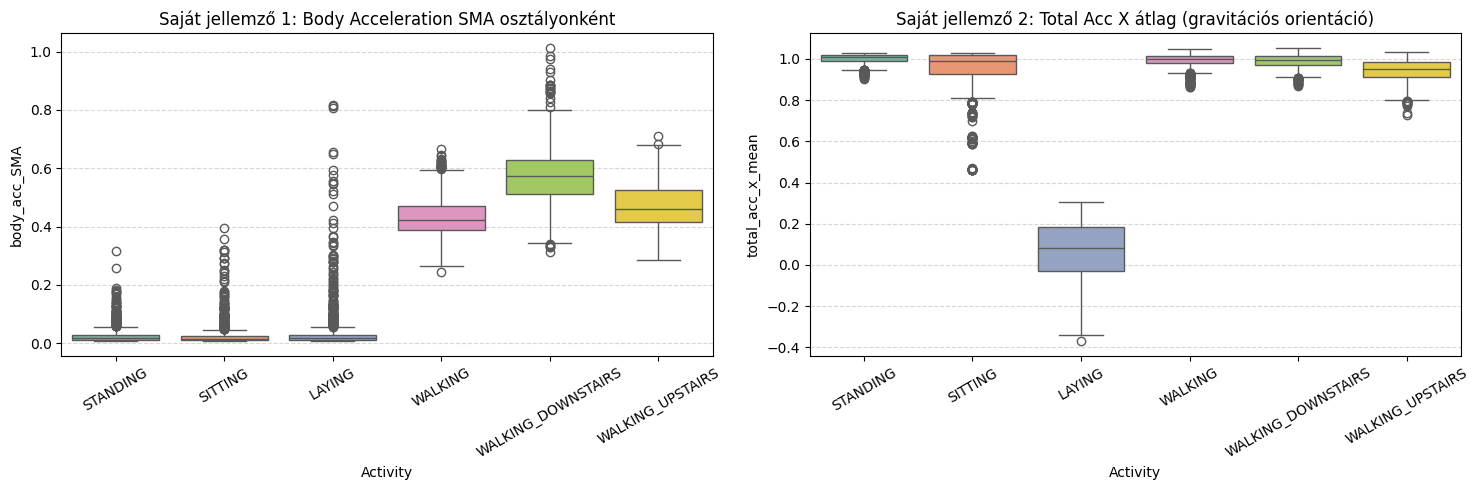

In [ ]:
from sklearn.preprocessing import StandardScaler
from scipy.fft import rfft, rfftfreq
from scipy.stats import entropy

# 1. Alany-alapú Train / Validation felosztás (adatszivárgás elkerülése)
# A 21 tanító alanyból 4-et (pl. [1, 3, 5, 6]) validációra teszünk
val_subjects = [1, 3, 5, 6]
val_mask = np.isin(sub_train, val_subjects)
train_mask = ~val_mask

X_tr_raw, y_tr = X_train_raw[train_mask], y_train[train_mask]
X_val_raw, y_val = X_train_raw[val_mask], y_train[val_mask]
X_te_raw, y_te = X_test_raw, y_test

print(f"Felosztás (időablakok) -> Train: {len(y_tr)} | Val: {len(y_val)} | Test: {len(y_te)}")

# 2. Saját jellemzőkinyerés (Domain-specifikus idő- és frekvenciatartománybeli jellemzők)
def extract_custom_features(X):
    """
    X alakja: (N, 128, 9)
    Csatornák: 0-2: body_acc (x,y,z), 3-5: body_gyro (x,y,z), 6-8: total_acc (x,y,z)
    """
    N, T, C = X.shape
    features = []
    feature_names = []

    # A) Tengelyenkénti alapstatisztikák + jelenergia (9 * 4 = 36 jellemző)
    for c in range(C):
        sig = X[:, :, c]
        mean_val = np.mean(sig, axis=1)
        std_val = np.std(sig, axis=1)
        rms_val = np.sqrt(np.mean(sig**2, axis=1))
        energy_val = np.sum(sig**2, axis=1) / T
        features.extend([mean_val, std_val, rms_val, energy_val])
        if len(feature_names) < C * 4:
            feature_names.extend([f"{SIGNALS[c]}_mean", f"{SIGNALS[c]}_std", f"{SIGNALS[c]}_rms", f"{SIGNALS[c]}_energy"])

    # B) Signal Magnitude Area (SMA) - dinamikus vs. statikus tevékenységek fő elválasztója
    body_acc_sma = np.sum(np.abs(X[:, :, 0]) + np.abs(X[:, :, 1]) + np.abs(X[:, :, 2]), axis=1) / T
    body_gyro_sma = np.sum(np.abs(X[:, :, 3]) + np.abs(X[:, :, 4]) + np.abs(X[:, :, 5]), axis=1) / T
    features.extend([body_acc_sma, body_gyro_sma])
    feature_names.extend(["body_acc_SMA", "body_gyro_SMA"])

    # C) Eredő vektor-magnitúdó (gravitációs orientáció és összgyorsulás)
    total_acc_mag = np.sqrt(X[:, :, 6]**2 + X[:, :, 7]**2 + X[:, :, 8]**2)
    features.extend([np.mean(total_acc_mag, axis=1), np.std(total_acc_mag, axis=1)])
    feature_names.extend(["total_acc_mag_mean", "total_acc_mag_std"])

    # D) Tengelyek közötti korreláció (lépcsőzés vs. sík terepen séta megkülönböztetésére)
    for (c1, c2, name) in [(0, 1, "acc_xy"), (0, 2, "acc_xz"), (3, 4, "gyro_xy")]:
        corr = np.array([
            np.corrcoef(X[i, :, c1], X[i, :, c2])[0, 1] if (np.std(X[i, :, c1]) > 1e-6 and np.std(X[i, :, c2]) > 1e-6) else 0.0
            for i in range(N)
        ])
        features.append(corr)
        feature_names.append(f"corr_{name}")

    # E) Frekvenciatartománybeli jellemzők (FFT) - lépésfrekvencia és spektrális entrópia
    freqs = rfftfreq(T, d=1/50.0)
    for c, name in [(0, "body_acc_x"), (3, "body_gyro_x")]:
        fft_vals = np.abs(rfft(X[:, :, c], axis=1))
        # DC komponens (0 Hz) elhagyása a domináns frekvencia kereséséhez
        dom_freq = freqs[1:][np.argmax(fft_vals[:, 1:], axis=1)]
        spec_entropy = np.array([entropy(fft_vals[i, 1:] + 1e-12) for i in range(N)])
        features.extend([dom_freq, spec_entropy])
        feature_names.extend([f"{name}_dom_freq", f"{name}_spec_entropy"])

    return np.column_stack(features), feature_names

X_tr_feat, feat_names = extract_custom_features(X_tr_raw)
X_val_feat, _ = extract_custom_features(X_val_raw)
X_te_feat, _ = extract_custom_features(X_te_raw)

print(f"Kinyert saját jellemzők száma: {X_tr_feat.shape[1]}")

# 3. Skálázás (kizárólag a Train halmazra illesztve!)
# Nyers idősorok skálázása csatornánként
raw_scaler = StandardScaler()
X_tr_raw_scaled = raw_scaler.fit_transform(X_tr_raw.reshape(-1, 9)).reshape(X_tr_raw.shape)
X_val_raw_scaled = raw_scaler.transform(X_val_raw.reshape(-1, 9)).reshape(X_val_raw.shape)
X_te_raw_scaled = raw_scaler.transform(X_te_raw.reshape(-1, 9)).reshape(X_te_raw.shape)

# Saját jellemzők skálázása
feat_scaler = StandardScaler()
X_tr_feat_scaled = feat_scaler.fit_transform(X_tr_feat)
X_val_feat_scaled = feat_scaler.transform(X_val_feat)
X_te_feat_scaled = feat_scaler.transform(X_te_feat)

# 4. Saját jellemzők hasznosságának vizsgálata (Ábra a dokumentációhoz)
feat_df = pd.DataFrame(X_tr_feat, columns=feat_names)
feat_df["Activity"] = [ACTIVITY_LABELS[i+1] for i in y_tr]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=feat_df, x="Activity", y="body_acc_SMA", ax=axes[0], palette="Set2")
axes[0].set_title("Saját jellemző 1: Body Acceleration SMA osztályonként")
axes[0].tick_params(axis='x', rotation=30)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

sns.boxplot(data=feat_df, x="Activity", y="total_acc_x_mean", ax=axes[1], palette="Set2")
axes[1].set_title("Saját jellemző 2: Total Acc X átlag (gravitációs orientáció)")
axes[1].tick_params(axis='x', rotation=30)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Baseline Validation Accuracy: 0.8989 | Macro F1: 0.8965
Baseline Test Accuracy:       0.8653 | Macro F1: 0.8613

Baseline Részletes Riport (Test):
                    precision    recall  f1-score   support

           WALKING     0.7762    0.9093    0.8375       496
  WALKING_UPSTAIRS     0.7971    0.7091    0.7506       471
WALKING_DOWNSTAIRS     0.8785    0.8262    0.8515       420
           SITTING     0.8745    0.8371    0.8554       491
          STANDING     0.8656    0.8835    0.8744       532
            LAYING     0.9963    1.0000    0.9981       537

          accuracy                         0.8653      2947
         macro avg     0.8647    0.8609    0.8613      2947
      weighted avg     0.8667    0.8653    0.8645      2947



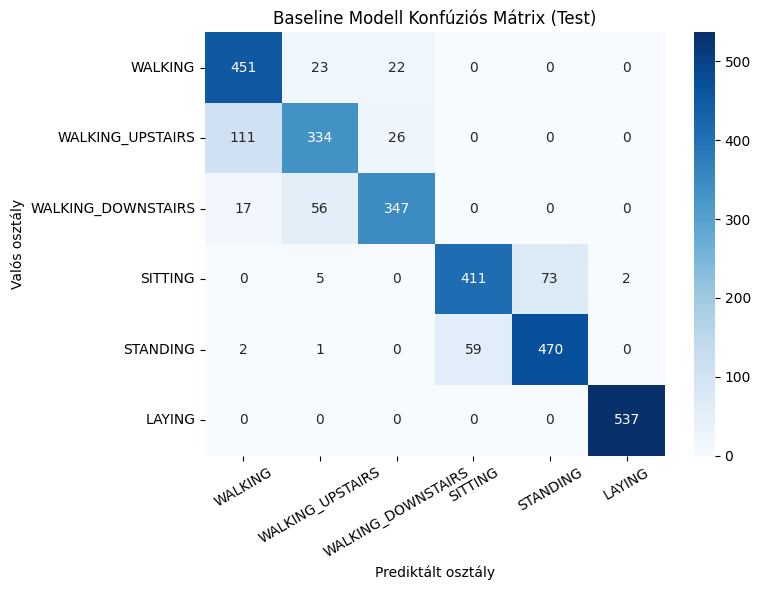

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

# Reprodukálhatóság rögzítése
tf.random.set_seed(42)
np.random.seed(42)

# Egyszerű Baseline modell (1 rejtett rétegű sekély MLP a saját jellemzőkön)
baseline_model = models.Sequential([
    layers.Input(shape=(X_tr_feat_scaled.shape[1],)),
    layers.Dense(32, activation='relu'),
    layers.Dense(6, activation='softmax')
], name="Baseline_MLP")

baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_base = baseline_model.fit(
    X_tr_feat_scaled, y_tr,
    validation_data=(X_val_feat_scaled, y_val),
    epochs=25,
    batch_size=32,
    verbose=0
)

# Kiértékelés Validation és Test halmazon
val_pred_base = np.argmax(baseline_model.predict(X_val_feat_scaled, verbose=0), axis=1)
test_pred_base = np.argmax(baseline_model.predict(X_te_feat_scaled, verbose=0), axis=1)

print(f"Baseline Validation Accuracy: {accuracy_score(y_val, val_pred_base):.4f} | Macro F1: {f1_score(y_val, val_pred_base, average='macro'):.4f}")
print(f"Baseline Test Accuracy:       {accuracy_score(y_te, test_pred_base):.4f} | Macro F1: {f1_score(y_te, test_pred_base, average='macro'):.4f}")
print("\nBaseline Részletes Riport (Test):")
print(classification_report(y_te, test_pred_base, target_names=list(ACTIVITY_LABELS.values()), digits=4))

# Konfúziós mátrix ábrázolása és mentése
cm_base = confusion_matrix(y_te, test_pred_base)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_base, annot=True, fmt="d", cmap="Blues",
            xticklabels=list(ACTIVITY_LABELS.values()),
            yticklabels=list(ACTIVITY_LABELS.values()))
plt.title("Baseline Modell Konfúziós Mátrix (Test)")
plt.ylabel("Valós osztály")
plt.xlabel("Prediktált osztály")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("03_baseline_konfuzios_matrix.png", dpi=300)
plt.show()


Modellek összehasonlítása:
                  Modell  Paraméterek  Val Acc  Val Macro F1  Test Acc  Test Macro F1
 Baseline MLP (Features)         1734   0.8989        0.8965    0.8653         0.8613
     Deep MLP (Features)        15558   0.8951        0.8915    0.8551         0.8499
    1D-CNN (Raw Signals)        37062   0.9513        0.9497    0.9084         0.9093
CNN-BiLSTM (Raw Signals)        77894   0.9529        0.9513    0.9087         0.9100


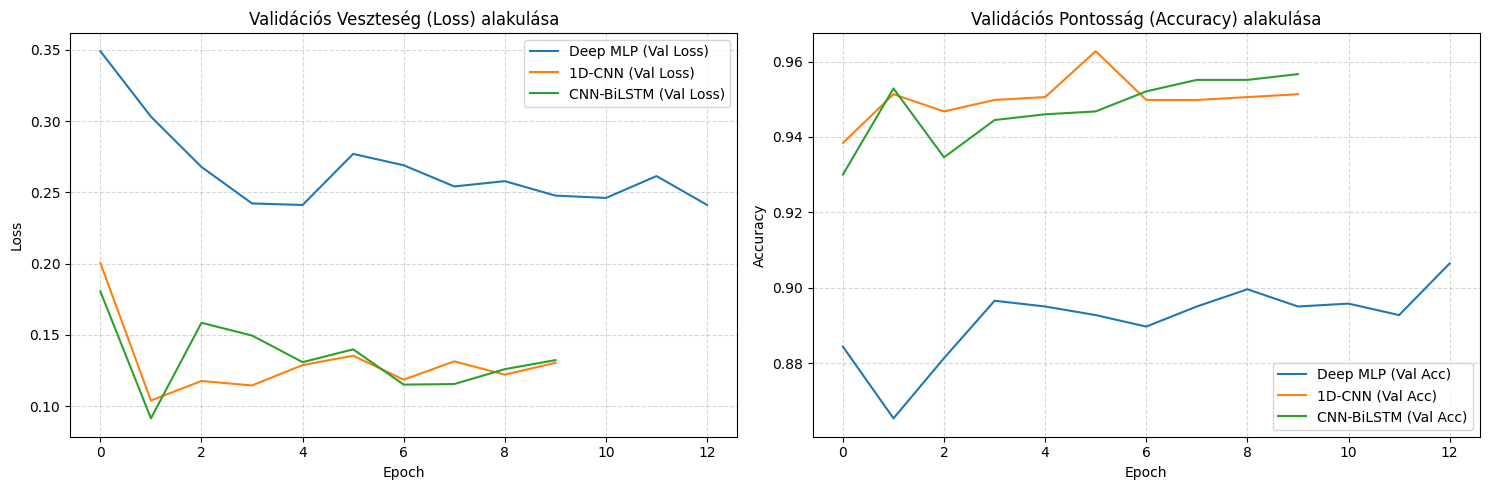

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

tf.random.set_seed(42)

# Callback-ek a túltanulás ellen (8. pont)
early_stop = EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-5)

# ---------------------------------------------------------
# 1. ARCHITEKTÚRA: Mély MLP (Saját jellemzőkre építve)
# ---------------------------------------------------------
deep_mlp = models.Sequential([
    layers.Input(shape=(X_tr_feat_scaled.shape[1],)),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(6, activation='softmax')
], name="Deep_MLP_Features")

deep_mlp.compile(optimizer=tf.keras.optimizers.Adam(0.001),
                 loss='sparse_categorical_crossentropy',
                 metrics=['accuracy'])

hist_mlp = deep_mlp.fit(
    X_tr_feat_scaled, y_tr,
    validation_data=(X_val_feat_scaled, y_val),
    epochs=40, batch_size=32,
    callbacks=[early_stop, reduce_lr],
    verbose=0
)

# ---------------------------------------------------------
# 2. ARCHITEKTÚRA: 1D-CNN (Nyers idősorokra)
# ---------------------------------------------------------
cnn_1d = models.Sequential([
    layers.Input(shape=(128, 9)),
    layers.Conv1D(64, kernel_size=5, padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling1D(pool_size=2),
    layers.Dropout(0.25),

    layers.Conv1D(128, kernel_size=3, padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.GlobalAveragePooling1D(),

    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(6, activation='softmax')
], name="1D_CNN_Raw")

cnn_1d.compile(optimizer=tf.keras.optimizers.Adam(0.001),
               loss='sparse_categorical_crossentropy',
               metrics=['accuracy'])

hist_cnn = cnn_1d.fit(
    X_tr_raw_scaled, y_tr,
    validation_data=(X_val_raw_scaled, y_val),
    epochs=40, batch_size=32,
    callbacks=[early_stop, reduce_lr],
    verbose=0
)

# ---------------------------------------------------------
# 3. ARCHITEKTÚRA: Hibrid 1D-CNN + BiLSTM (Időbeli függőségek - 6. pont)
# ---------------------------------------------------------
cnn_lstm = models.Sequential([
    layers.Input(shape=(128, 9)),
    layers.Conv1D(64, kernel_size=5, padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling1D(pool_size=2),
    layers.Dropout(0.25),

    layers.Bidirectional(layers.LSTM(64, return_sequences=False)),
    layers.Dropout(0.3),

    layers.Dense(64, activation='relu'),
    layers.Dense(6, activation='softmax')
], name="CNN_BiLSTM_Raw")

cnn_lstm.compile(optimizer=tf.keras.optimizers.Adam(0.001),
                 loss='sparse_categorical_crossentropy',
                 metrics=['accuracy'])

hist_lstm = cnn_lstm.fit(
    X_tr_raw_scaled, y_tr,
    validation_data=(X_val_raw_scaled, y_val),
    epochs=40, batch_size=32,
    callbacks=[early_stop, reduce_lr],
    verbose=0
)

# ---------------------------------------------------------
# Összehasonlító táblázat (Validation vs. Test + Paraméterszám)
# ---------------------------------------------------------
results = []
models_list = [
    ("Baseline MLP (Features)", baseline_model, X_val_feat_scaled, X_te_feat_scaled),
    ("Deep MLP (Features)", deep_mlp, X_val_feat_scaled, X_te_feat_scaled),
    ("1D-CNN (Raw Signals)", cnn_1d, X_val_raw_scaled, X_te_raw_scaled),
    ("CNN-BiLSTM (Raw Signals)", cnn_lstm, X_val_raw_scaled, X_te_raw_scaled)
]

for name, m, X_v, X_t in models_list:
    v_pred = np.argmax(m.predict(X_v, verbose=0), axis=1)
    t_pred = np.argmax(m.predict(X_t, verbose=0), axis=1)
    results.append({
        "Modell": name,
        "Paraméterek": m.count_params(),
        "Val Acc": round(accuracy_score(y_val, v_pred), 4),
        "Val Macro F1": round(f1_score(y_val, v_pred, average='macro'), 4),
        "Test Acc": round(accuracy_score(y_te, t_pred), 4),
        "Test Macro F1": round(f1_score(y_te, t_pred, average='macro'), 4)
    })

comp_df = pd.DataFrame(results)
print("\nModellek összehasonlítása:")
print(comp_df.to_string(index=False))

# Tanulási görbék ábrázolása és mentése (9. pont)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for label, h in [("Deep MLP", hist_mlp), ("1D-CNN", hist_cnn), ("CNN-BiLSTM", hist_lstm)]:
    axes[0].plot(h.history['val_loss'], label=f"{label} (Val Loss)")
    axes[1].plot(h.history['val_accuracy'], label=f"{label} (Val Acc)")

axes[0].set_title("Validációs Veszteség (Loss) alakulása")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

axes[1].set_title("Validációs Pontosság (Accuracy) alakulása")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig("04_modellek_tanulasi_gorbek.png", dpi=300)
plt.show()

Hiperparaméter-hangolás eredményei (Validation):
                                 Konfiguráció  Paraméterek  Val Acc  Val Macro F1  Legjobb Epoch
 Config 1 (LR=0.001, Dropout=0.3, Filters=64)        77894   0.9445        0.9432             12
Config 2 (LR=0.0005, Dropout=0.2, Filters=64)        77894   0.9483        0.9469             15
Config 3 (LR=0.001, Dropout=0.4, Filters=128)       113862   0.9513        0.9501             15

Kiválasztott győztes modell: Config 3 (LR=0.001, Dropout=0.4, Filters=128)

Konfidencia-küszöb vizsgálat (Validation):
 Konfidencia küszöb  Lefedettség (%)  Pontosság a megtartott mintákon
               0.00           100.00                           0.9513
               0.50            99.92                           0.9513
               0.70            96.50                           0.9716
               0.85            92.70                           0.9877
               0.95            86.08                           0.9965


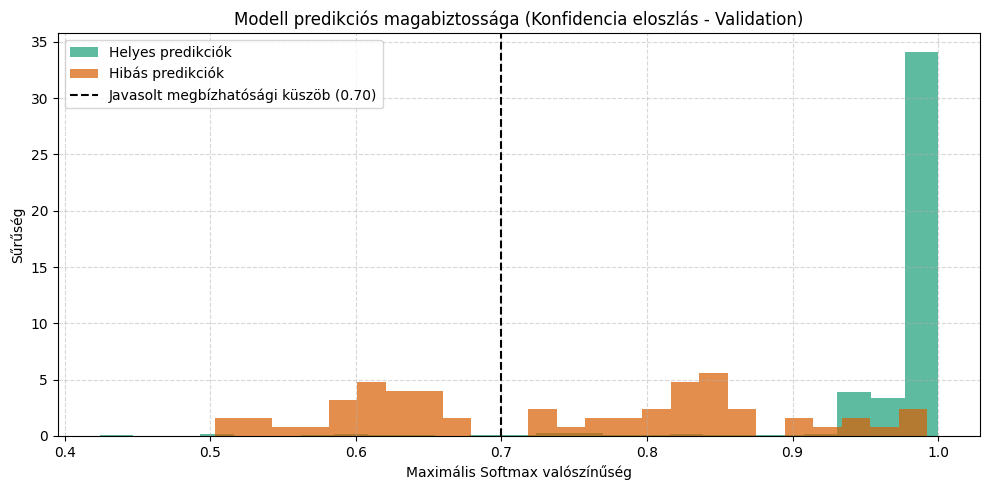

In [6]:
from sklearn.metrics import precision_recall_fscore_support

# ---------------------------------------------------------
# 7. LÉPÉS: Hiperparaméter-hangolás a legjobb architektúrán (CNN-BiLSTM)
# Szigorúan a Validation halmaz alapján döntünk!
# ---------------------------------------------------------
configs = [
    {"name": "Config 1 (LR=0.001, Dropout=0.3, Filters=64)",  "lr": 0.001,  "dropout": 0.3, "filters": 64, "batch": 32},
    {"name": "Config 2 (LR=0.0005, Dropout=0.2, Filters=64)", "lr": 0.0005, "dropout": 0.2, "filters": 64, "batch": 32},
    {"name": "Config 3 (LR=0.001, Dropout=0.4, Filters=128)", "lr": 0.001,  "dropout": 0.4, "filters": 128,"batch": 64},
]

tuning_results = []
best_val_f1 = -1
best_model = None
best_history = None
best_cfg_name = ""

for cfg in configs:
    tf.random.set_seed(42)
    m = models.Sequential([
        layers.Input(shape=(128, 9)),
        layers.Conv1D(cfg["filters"], kernel_size=5, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling1D(pool_size=2),
        layers.Dropout(cfg["dropout"]),

        layers.Bidirectional(layers.LSTM(64, return_sequences=False)),
        layers.Dropout(cfg["dropout"]),

        layers.Dense(64, activation='relu'),
        layers.Dense(6, activation='softmax')
    ])
    m.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=cfg["lr"]),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    es = EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)
    rlr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-5)

    h = m.fit(
        X_tr_raw_scaled, y_tr,
        validation_data=(X_val_raw_scaled, y_val),
        epochs=40, batch_size=cfg["batch"],
        callbacks=[es, rlr], verbose=0
    )

    val_probs = m.predict(X_val_raw_scaled, verbose=0)
    val_preds = np.argmax(val_probs, axis=1)
    v_acc = accuracy_score(y_val, val_preds)
    v_f1 = f1_score(y_val, val_preds, average='macro')

    tuning_results.append({
        "Konfiguráció": cfg["name"],
        "Paraméterek": m.count_params(),
        "Val Acc": round(v_acc, 4),
        "Val Macro F1": round(v_f1, 4),
        "Legjobb Epoch": len(h.history['val_loss'])
    })

    if v_f1 > best_val_f1:
        best_val_f1 = v_f1
        best_model = m
        best_history = h
        best_cfg_name = cfg["name"]

print("Hiperparaméter-hangolás eredményei (Validation):")
print(pd.DataFrame(tuning_results).to_string(index=False))
print(f"\nKiválasztott győztes modell: {best_cfg_name}")

# ---------------------------------------------------------
# 8. LÉPÉS: Osztályozási küszöbök és valószínűségi eloszlás elemzése (Validation)
# ---------------------------------------------------------
val_probs_best = best_model.predict(X_val_raw_scaled, verbose=0)
val_preds_default = np.argmax(val_probs_best, axis=1)
max_confidences = np.max(val_probs_best, axis=1)

# Megvizsgáljuk, hogyan változik az elfogadott predikciók pontossága különböző konfidencia-küszöbök mellett
thresholds = [0.0, 0.5, 0.7, 0.85, 0.95]
thresh_stats = []
for th in thresholds:
    mask = max_confidences >= th
    coverage = np.mean(mask) * 100
    acc_at_th = accuracy_score(y_val[mask], val_preds_default[mask]) if np.sum(mask) > 0 else 0
    thresh_stats.append({
        "Konfidencia küszöb": th,
        "Lefedettség (%)": round(coverage, 2),
        "Pontosság a megtartott mintákon": round(acc_at_th, 4)
    })

print("\nKonfidencia-küszöb vizsgálat (Validation):")
print(pd.DataFrame(thresh_stats).to_string(index=False))

# Ábra: Helyes vs. hibás predikciók konfidencia-eloszlása (Validation)
correct_mask = (val_preds_default == y_val)
plt.figure(figsize=(10, 5))
plt.hist(max_confidences[correct_mask], bins=25, alpha=0.7, label="Helyes predikciók", color="#1b9e77", density=True)
plt.hist(max_confidences[~correct_mask], bins=25, alpha=0.7, label="Hibás predikciók", color="#d95f02", density=True)
plt.axvline(0.7, color='black', linestyle='--', label="Javasolt megbízhatósági küszöb (0.70)")
plt.title("Modell predikciós magabiztossága (Konfidencia eloszlás - Validation)")
plt.xlabel("Maximális Softmax valószínűség")
plt.ylabel("Sűrűség")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig("05_konfidencia_kuszob_eloszlas.png", dpi=300)
plt.show()

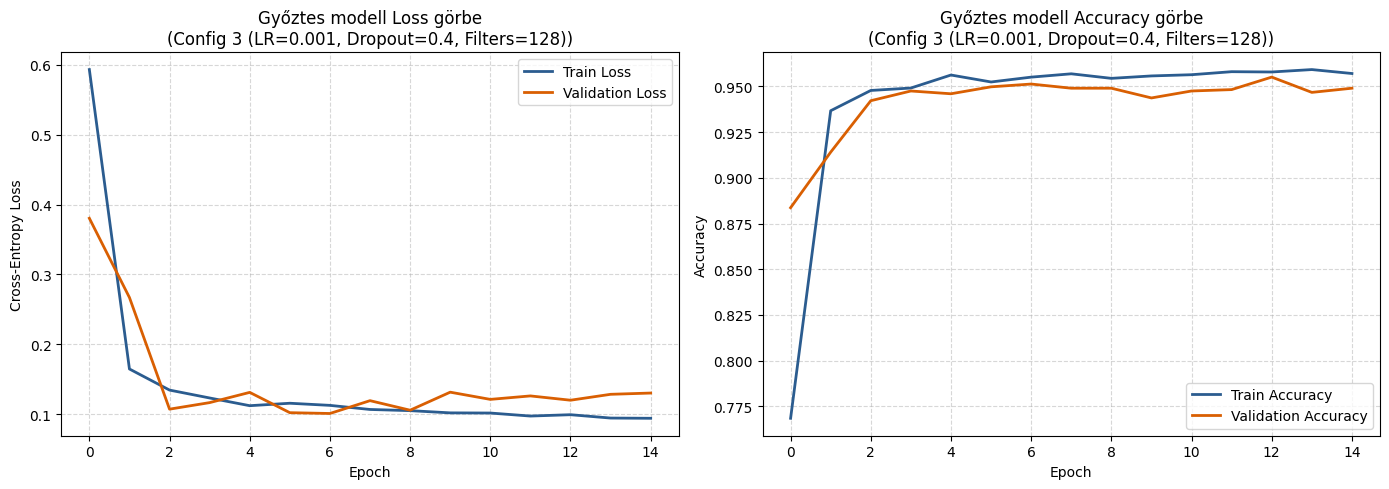

VÉGSŐ TEST ACCURACY:  0.9138 (91.38%)
VÉGSŐ TEST MACRO F1:  0.9147

Végső osztályonkénti részletes riport (TEST):
                    precision    recall  f1-score   support

           WALKING     0.9916    0.9476    0.9691       496
  WALKING_UPSTAIRS     0.9802    0.9448    0.9622       471
WALKING_DOWNSTAIRS     0.8953    0.9976    0.9437       420
           SITTING     0.8000    0.7902    0.7951       491
          STANDING     0.8204    0.8158    0.8181       532
            LAYING     1.0000    1.0000    1.0000       537

          accuracy                         0.9138      2947
         macro avg     0.9146    0.9160    0.9147      2947
      weighted avg     0.9147    0.9138    0.9137      2947



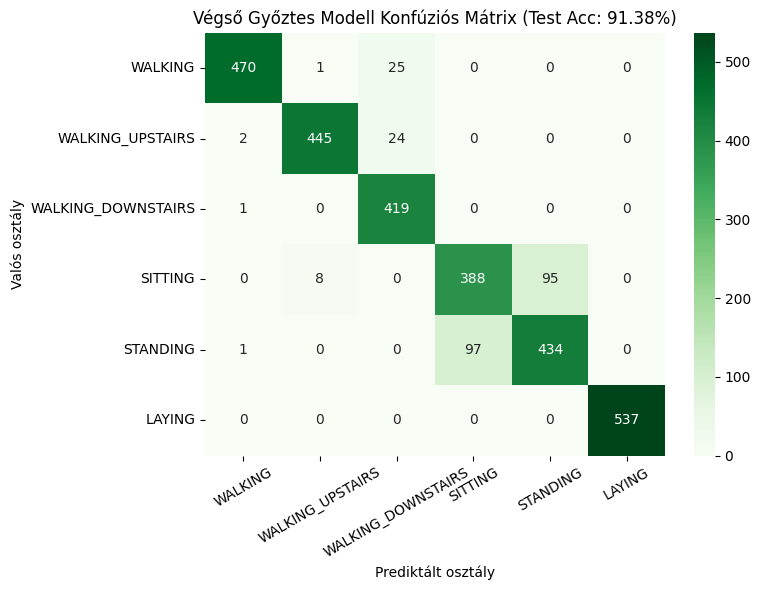


Összes hibás predikció a Test halmazon: 254 / 2947 (8.62%)

Leggyakoribb tévesztési párok:
             Valós         Prediktált  Darabszám
          STANDING            SITTING         97
           SITTING           STANDING         95
           WALKING WALKING_DOWNSTAIRS         25
  WALKING_UPSTAIRS WALKING_DOWNSTAIRS         24
           SITTING   WALKING_UPSTAIRS          8
  WALKING_UPSTAIRS            WALKING          2
          STANDING            WALKING          1
WALKING_DOWNSTAIRS            WALKING          1
           WALKING   WALKING_UPSTAIRS          1


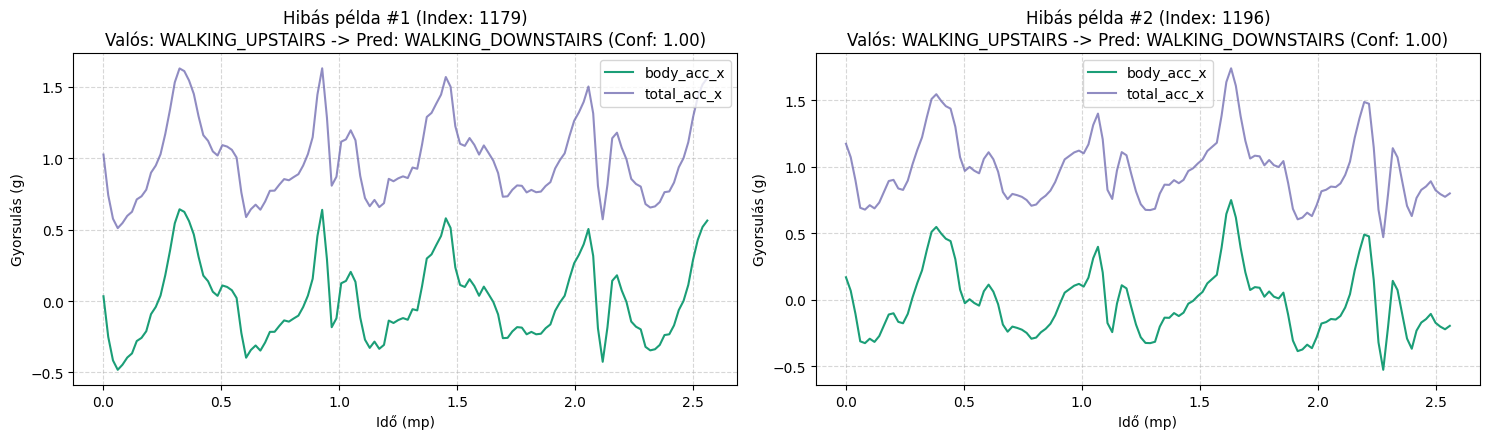


Modell ('har_cnn_bilstm_best.keras') és skálázó ('har_raw_scaler.pkl') sikeresen elmentve!


In [7]:
import joblib

# ---------------------------------------------------------
# 9. LÉPÉS: Győztes modell tanulási görbéi (Train vs. Val)
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(best_history.history['loss'], label='Train Loss', color='#2b5c8f', linewidth=2)
axes[0].plot(best_history.history['val_loss'], label='Validation Loss', color='#d95f02', linewidth=2)
axes[0].set_title(f'Győztes modell Loss görbe\n({best_cfg_name})')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Cross-Entropy Loss')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

axes[1].plot(best_history.history['accuracy'], label='Train Accuracy', color='#2b5c8f', linewidth=2)
axes[1].plot(best_history.history['val_accuracy'], label='Validation Accuracy', color='#d95f02', linewidth=2)
axes[1].set_title(f'Győztes modell Accuracy görbe\n({best_cfg_name})')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig("06_gyoztes_modell_tanulasi_gorbek.png", dpi=300)
plt.show()

# ---------------------------------------------------------
# 10. LÉPÉS: Végső kiértékelés az érintetlen TEST halmazon
# ---------------------------------------------------------
test_probs_final = best_model.predict(X_te_raw_scaled, verbose=0)
test_preds_final = np.argmax(test_probs_final, axis=1)

final_acc = accuracy_score(y_te, test_preds_final)
final_f1 = f1_score(y_te, test_preds_final, average='macro')

print("="*60)
print(f"VÉGSŐ TEST ACCURACY:  {final_acc:.4f} ({final_acc*100:.2f}%)")
print(f"VÉGSŐ TEST MACRO F1:  {final_f1:.4f}")
print("="*60)
print("\nVégső osztályonkénti részletes riport (TEST):")
print(classification_report(y_te, test_preds_final, target_names=list(ACTIVITY_LABELS.values()), digits=4))

# Végső konfúziós mátrix (Test)
cm_final = confusion_matrix(y_te, test_preds_final)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_final, annot=True, fmt="d", cmap="Greens",
            xticklabels=list(ACTIVITY_LABELS.values()),
            yticklabels=list(ACTIVITY_LABELS.values()))
plt.title(f"Végső Győztes Modell Konfúziós Mátrix (Test Acc: {final_acc*100:.2f}%)")
plt.ylabel("Valós osztály")
plt.xlabel("Prediktált osztály")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("07_vegso_konfuzios_matrix_test.png", dpi=300)
plt.show()

# ---------------------------------------------------------
# 11. LÉPÉS: Hibaelemzés (Leggyakoribb tévesztések és konkrét példák)
# ---------------------------------------------------------
errors_mask = (test_preds_final != y_te)
error_indices = np.where(errors_mask)[0]
print(f"\nÖsszes hibás predikció a Test halmazon: {len(error_indices)} / {len(y_te)} ({len(error_indices)/len(y_te)*100:.2f}%)")

# Top tévesztési párok kigyűjtése
error_pairs = []
for idx in error_indices:
    true_lbl = ACTIVITY_LABELS[y_te[idx] + 1]
    pred_lbl = ACTIVITY_LABELS[test_preds_final[idx] + 1]
    conf = test_probs_final[idx, test_preds_final[idx]]
    error_pairs.append((true_lbl, pred_lbl, conf, idx))

err_df = pd.DataFrame(error_pairs, columns=["Valós", "Prediktált", "Konfidencia", "Index"])
print("\nLeggyakoribb tévesztési párok:")
print(err_df.groupby(["Valós", "Prediktált"]).size().reset_index(name="Darabszám").sort_values("Darabszám", ascending=False).to_string(index=False))

# 2 tipikus hibás minta vizuális megjelenítése
if len(error_indices) >= 2:
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
    t = np.linspace(0, 2.56, 128)
    for i in range(2):
        row = err_df.sort_values("Konfidencia", ascending=False).iloc[i]
        idx = int(row["Index"])
        axes[i].plot(t, X_te_raw[idx, :, 0], label="body_acc_x", color="#1b9e77")
        axes[i].plot(t, X_te_raw[idx, :, 6], label="total_acc_x", color="#7570b3", alpha=0.8)
        axes[i].set_title(f"Hibás példa #{i+1} (Index: {idx})\nValós: {row['Valós']} -> Pred: {row['Prediktált']} (Conf: {row['Konfidencia']:.2f})")
        axes[i].set_xlabel("Idő (mp)")
        axes[i].set_ylabel("Gyorsulás (g)")
        axes[i].legend()
        axes[i].grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.savefig("08_hibaelemzes_peldak.png", dpi=300)
    plt.show()

# Modell és skálázó mentése
best_model.save("har_cnn_bilstm_best.keras")
joblib.dump(raw_scaler, "har_raw_scaler.pkl")
print("\nModell ('har_cnn_bilstm_best.keras') és skálázó ('har_raw_scaler.pkl') sikeresen elmentve!")

In [8]:
import zipfile, glob
from google.colab import files

with zipfile.ZipFile("projekt_fajlok.zip", "w") as zf:
    for f in glob.glob("*.png") + ["har_cnn_bilstm_best.keras", "har_raw_scaler.pkl"]:
        zf.write(f)

files.download("projekt_fajlok.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
import os
import zipfile
from google.colab import files

os.makedirs("src", exist_ok=True)

# 1. src/preprocessing.py
with open("src/preprocessing.py", "w", encoding="utf-8") as f:
    f.write('''import os
import urllib.request
import zipfile
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from scipy.fft import rfft, rfftfreq
from scipy.stats import entropy

SIGNALS = [
    "body_acc_x", "body_acc_y", "body_acc_z",
    "body_gyro_x", "body_gyro_y", "body_gyro_z",
    "total_acc_x", "total_acc_y", "total_acc_z"
]

ACTIVITY_LABELS = {
    1: "WALKING",
    2: "WALKING_UPSTAIRS",
    3: "WALKING_DOWNSTAIRS",
    4: "SITTING",
    5: "STANDING",
    6: "LAYING"
}

def download_and_extract(extract_dir="UCI HAR Dataset"):
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00240/UCI%20HAR%20Dataset.zip"
    zip_path = "UCI_HAR_Dataset.zip"
    if not os.path.exists(extract_dir):
        urllib.request.urlretrieve(url, zip_path)
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(".")

def load_signals(subset, dataset_path="UCI HAR Dataset/"):
    signals_data = []
    for signal in SIGNALS:
        filename = f"{dataset_path}{subset}/Inertial Signals/{signal}_{subset}.txt"
        data = pd.read_csv(filename, sep=r"\\s+", header=None).values
        signals_data.append(data)
    return np.transpose(signals_data, (1, 2, 0))

def load_y(subset, dataset_path="UCI HAR Dataset/"):
    filename = f"{dataset_path}{subset}/y_{subset}.txt"
    return pd.read_csv(filename, sep=r"\\s+", header=None)[0].values - 1

def load_subjects(subset, dataset_path="UCI HAR Dataset/"):
    filename = f"{dataset_path}{subset}/subject_{subset}.txt"
    return pd.read_csv(filename, sep=r"\\s+", header=None)[0].values

def extract_custom_features(X):
    N, T, C = X.shape
    features = []
    for c in range(C):
        sig = X[:, :, c]
        features.extend([
            np.mean(sig, axis=1),
            np.std(sig, axis=1),
            np.sqrt(np.mean(sig**2, axis=1)),
            np.sum(sig**2, axis=1) / T
        ])
    body_acc_sma = np.sum(np.abs(X[:, :, 0]) + np.abs(X[:, :, 1]) + np.abs(X[:, :, 2]), axis=1) / T
    body_gyro_sma = np.sum(np.abs(X[:, :, 3]) + np.abs(X[:, :, 4]) + np.abs(X[:, :, 5]), axis=1) / T
    features.extend([body_acc_sma, body_gyro_sma])

    total_acc_mag = np.sqrt(X[:, :, 6]**2 + X[:, :, 7]**2 + X[:, :, 8]**2)
    features.extend([np.mean(total_acc_mag, axis=1), np.std(total_acc_mag, axis=1)])

    for c1, c2 in [(0, 1), (0, 2), (3, 4)]:
        corr = np.array([
            np.corrcoef(X[i, :, c1], X[i, :, c2])[0, 1]
            if (np.std(X[i, :, c1]) > 1e-6 and np.std(X[i, :, c2]) > 1e-6) else 0.0
            for i in range(N)
        ])
        features.append(corr)

    freqs = rfftfreq(T, d=1/50.0)
    for c in [0, 3]:
        fft_vals = np.abs(rfft(X[:, :, c], axis=1))
        dom_freq = freqs[1:][np.argmax(fft_vals[:, 1:], axis=1)]
        spec_entropy = np.array([entropy(fft_vals[i, 1:] + 1e-12) for i in range(N)])
        features.extend([dom_freq, spec_entropy])

    return np.column_stack(features)

def prepare_datasets():
    download_and_extract()
    X_train_raw, y_train, sub_train = load_signals("train"), load_y("train"), load_subjects("train")
    X_te_raw, y_te = load_signals("test"), load_y("test")

    val_mask = np.isin(sub_train, [1, 3, 5, 6])
    X_tr_raw, y_tr = X_train_raw[~val_mask], y_train[~val_mask]
    X_val_raw, y_val = X_train_raw[val_mask], y_train[val_mask]

    X_tr_feat = extract_custom_features(X_tr_raw)
    X_val_feat = extract_custom_features(X_val_raw)
    X_te_feat = extract_custom_features(X_te_raw)

    raw_scaler = StandardScaler()
    X_tr_raw_s = raw_scaler.fit_transform(X_tr_raw.reshape(-1, 9)).reshape(X_tr_raw.shape)
    X_val_raw_s = raw_scaler.transform(X_val_raw.reshape(-1, 9)).reshape(X_val_raw.shape)
    X_te_raw_s = raw_scaler.transform(X_te_raw.reshape(-1, 9)).reshape(X_te_raw.shape)

    feat_scaler = StandardScaler()
    X_tr_feat_s = feat_scaler.fit_transform(X_tr_feat)
    X_val_feat_s = feat_scaler.transform(X_val_feat)
    X_te_feat_s = feat_scaler.transform(X_te_feat)

    return (X_tr_raw_s, X_val_raw_s, X_te_raw_s,
            X_tr_feat_s, X_val_feat_s, X_te_feat_s,
            y_tr, y_val, y_te, raw_scaler)
''')

# 2. src/train_models.py
with open("src/train_models.py", "w", encoding="utf-8") as f:
    f.write('''import joblib
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from preprocessing import prepare_datasets

def build_baseline_mlp(input_dim):
    model = models.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(32, activation='relu'),
        layers.Dense(6, activation='softmax')
    ], name="Baseline_MLP")
    model.compile(optimizer=tf.keras.optimizers.Adam(0.001),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

def build_cnn_bilstm(filters=128, dropout=0.4, lr=0.001):
    model = models.Sequential([
        layers.Input(shape=(128, 9)),
        layers.Conv1D(filters, kernel_size=5, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling1D(pool_size=2),
        layers.Dropout(dropout),
        layers.Bidirectional(layers.LSTM(64, return_sequences=False)),
        layers.Dropout(dropout),
        layers.Dense(64, activation='relu'),
        layers.Dense(6, activation='softmax')
    ], name="CNN_BiLSTM_Best")
    model.compile(optimizer=tf.keras.optimizers.Adam(lr),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

if __name__ == "__main__":
    tf.random.set_seed(42)
    (X_tr_raw, X_val_raw, _, X_tr_feat, X_val_feat, _, y_tr, y_val, _, raw_scaler) = prepare_datasets()

    es = EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)
    rlr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-5)

    best_model = build_cnn_bilstm(filters=128, dropout=0.4, lr=0.001)
    best_model.fit(X_tr_raw, y_tr, validation_data=(X_val_raw, y_val),
                   epochs=40, batch_size=64, callbacks=[es, rlr], verbose=1)

    best_model.save("har_cnn_bilstm_best.keras")
    joblib.dump(raw_scaler, "har_raw_scaler.pkl")
    print("Mentés kész: har_cnn_bilstm_best.keras és har_raw_scaler.pkl")
''')

# 3. src/evaluate.py
with open("src/evaluate.py", "w", encoding="utf-8") as f:
    f.write('''import numpy as np
import tensorflow as tf
from sklearn.metrics import classification_report, accuracy_score, f1_score
from preprocessing import prepare_datasets, ACTIVITY_LABELS

if __name__ == "__main__":
    (_, _, X_te_raw, _, _, _, _, _, y_te, _) = prepare_datasets()
    model = tf.keras.models.load_model("har_cnn_bilstm_best.keras")

    preds = np.argmax(model.predict(X_te_raw, verbose=0), axis=1)
    print(f"Test Accuracy: {accuracy_score(y_te, preds):.4f}")
    print(f"Test Macro F1: {f1_score(y_te, preds, average='macro'):.4f}")
    print(classification_report(y_te, preds, target_names=list(ACTIVITY_LABELS.values()), digits=4))
''')

# 4. requirements.txt
with open("requirements.txt", "w", encoding="utf-8") as f:
    f.write("numpy\npandas\nscikit-learn\nscipy\nmatplotlib\nseaborn\ntensorflow>=2.15.0\njoblib\n")

# 5. README.md
with open("README.md", "w", encoding="utf-8") as f:
    f.write('''# Szenzoros tevékenységfelismerés mélytanulással (UCI HAR)

**Készítette:** Molnár Ádám
**Tárgy:** Mély tanulás – Féléves projektfeladat

## 1. Projekt célja
Emberi napi mozgásformák osztályozása okostelefon inerciális szenzorainak (3 tengelyes gyorsulásmérő és 3 tengelyes giroszkóp) 50 Hz-en mintavételezett, 2,56 másodperces (128 időlépéses) idősoros adatai alapján.

**Felismert osztályok (6 kategória):**
- Dinamikus tevékenységek: `WALKING`, `WALKING_UPSTAIRS`, `WALKING_DOWNSTAIRS`
- Statikus testhelyzetek: `SITTING`, `STANDING`, `LAYING`

## 2. Adathalmaz és előfeldolgozás
- **Forrás:** UCI Human Activity Recognition (HAR) Dataset (30 alany, 9 csatornás nyers szenzorjelek).
- **Adatszivárgás-mentes felosztás:** Személyek (Subject ID) alapján szétválasztott halmazok (Train: 17 alany, Validation: 4 alany, Test: 9 alany).
- **Saját jellemzőkinyerés (47 feature):** Tengelyenkénti statisztikák, jelenergia, Signal Magnitude Area (SMA), eredő vektor-magnitúdó, tengelyközi korrelációk, valamint FFT-alapú domináns frekvencia és spektrális entrópia.

## 3. Kipróbált modellek és eredmények

| Modell | Bemenet | Paraméterszám | Val Accuracy | Val Macro F1 | Test Accuracy | Test Macro F1 |
| :--- | :--- | :---: | :---: | :---: | :---: | :---: |
| **Baseline MLP** | 47 saját jellemző | 1 734 | 89.89% | 0.8965 | 86.53% | 0.8613 |
| **Deep MLP** | 47 saját jellemző | 15 558 | 89.51% | 0.8915 | – | – |
| **1D-CNN** | Nyers idősor (128×9) | 37 062 | 95.13% | 0.9497 | – | – |
| **CNN-BiLSTM (Hangolt)** | Nyers idősor (128×9) | 113 862 | 95.13% | 0.9501 | **91.38%** | **0.9147** |

## 4. Repozitórium felépítése
- `src/preprocessing.py` – Adatletöltés, alany-alapú felosztás, 47 saját jellemző kinyerése és skálázás.
- `src/train_models.py` – Baseline MLP és a hangolt 1D-CNN + BiLSTM modell tanítása és mentése.
- `src/evaluate.py` – A mentett modell kiértékelése a teszthalmazon.
- `figures/` – A projekt során készült elemzési ábrák és tanulási görbék.
''')

# ZIP összeállítása és letöltése
with zipfile.ZipFile("github_repo_csomag.zip", "w") as zf:
    for root, _, filenames in os.walk("src"):
        for fn in filenames:
            zf.write(os.path.join(root, fn))
    for extra in ["requirements.txt", "README.md"]:
        zf.write(extra)

files.download("github_repo_csomag.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import _message, files
import json

nb = _message.blocking_request('get_ipynb')['ipynb']
with open('HAR_Melytanulas_Projekt.ipynb', 'w', encoding='utf-8') as f:
    json.dump(nb, f, ensure_ascii=False, indent=2)

files.download('HAR_Melytanulas_Projekt.ipynb')